# Analyse Statistique Descriptive d'une Variable : Le BMI
**Jeu de données :** `diabetes_012_health_indicators_BRFSS2015.csv`  

Ce carnet Jupyter effectue une analyse statistique univariée complète respectant les étapes suivantes :
1. **Sélection d'une variable** : l'Indice de Masse Corporelle (`BMI`).
2. **Calcul des mesures statistiques** : tendance centrale, dispersion et forme de distribution.
3. **Interprétation détaillée de ces mesures** dans le contexte épidémiologique.
4. **Visualisation graphique** : Histogramme avec estimation de densité (KDE), boîte à moustaches (Boxplot) et fonction de répartition empirique (ECDF).


## 1. Sélection et chargement de la variable

La variable retenue est **`BMI`** (*Body Mass Index* ou Indice de Masse Corporelle).  
Il s'agit d'une variable quantitative continue calculée par la formule $\text{BMI} = \frac{\text{Poids (kg)}}{\text{Taille (m)}^2}$.  
Elle constitue un facteur de risque majeur dans le développement du diabète de type 2 et des maladies cardiovasculaires.

Selon la classification de l'Organisation Mondiale de la Santé (OMS) :
- **$\text{BMI} < 18.5$** : Insuffisance pondérale (maigreur)
- **$18.5 \le \text{BMI} < 25$** : Corpulence normale
- **$25 \le \text{BMI} < 30$** : Surpoids
- **$\text{BMI} \ge 30$** : Obésité


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration visuelle
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Chargement du fichier de données
df = pd.read_csv('diabetes_012_health_indicators_BRFSS2015.csv')

# Extraction de la variable d'intérêt : BMI
bmi = df['BMI']

print(f"Variable sélectionnée : BMI")
print(f"Nombre total d'observations : {len(bmi):,}")
print(f"Nombre de valeurs manquantes (NaN) : {bmi.isnull().sum()}")
print(f"Type de données : {bmi.dtype}")


Variable sélectionnée : BMI
Nombre total d'observations : 253,680
Nombre de valeurs manquantes (NaN) : 0
Type de données : float64


## 2. Calcul des mesures statistiques

Nous calculons l'ensemble des indicateurs statistiques descriptifs pour la variable `BMI` :
- **Mesures de tendance centrale :** Moyenne, Médiane, Mode.
- **Mesures de dispersion :** Étendue (Range), Minimum, Maximum, Variance, Écart-type, Quartiles ($Q_1$, $Q_2$, $Q_3$) et Écart Interquartile ($IQR$).
- **Mesures de forme :** Coefficient d'asymétrie (*Skewness*) et Coefficient d'aplatissement (*Kurtosis*).


In [2]:
# 1. Mesures de tendance centrale
moyenne = float(bmi.mean())
mediane = float(bmi.median())
mode_val = float(bmi.mode()[0])

# 2. Mesures de dispersion
val_min = float(bmi.min())
val_max = float(bmi.max())
etendue = val_max - val_min
variance = float(bmi.var())
ecart_type = float(bmi.std())

q1 = float(bmi.quantile(0.25))
q3 = float(bmi.quantile(0.75))
iqr = q3 - q1

# 3. Mesures de forme
skewness = float(bmi.skew())
kurtosis = float(bmi.kurtosis())

# Présentation récapitulative sous forme de tableau
stats_summary = pd.DataFrame({
    'Mesure Statistique': [
        'Effectif total (N)',
        'Moyenne',
        'Médiane',
        'Mode',
        'Minimum',
        'Maximum',
        'Étendue (Range)',
        'Premier quartile (Q1 - 25%)',
        'Troisième quartile (Q3 - 75%)',
        'Écart interquartile (IQR)',
        'Variance',
        'Écart-type (Écart type empirique)',
        'Asymétrie (Skewness)',
        'Aplatissement (Kurtosis)'
    ],
    'Valeur': [
        f"{len(bmi):,}",
        f"{moyenne:.2f}",
        f"{mediane:.2f}",
        f"{mode_val:.2f}",
        f"{val_min:.2f}",
        f"{val_max:.2f}",
        f"{etendue:.2f}",
        f"{q1:.2f}",
        f"{q3:.2f}",
        f"{iqr:.2f}",
        f"{variance:.2f}",
        f"{ecart_type:.2f}",
        f"{skewness:.2f}",
        f"{kurtosis:.2f}"
    ]
})

stats_summary


,Mesure Statistique,Valeur
0,Effectif total (N),"253,680"
1,Moyenne,28.38
2,Médiane,27.00
3,Mode,27.00
4,Minimum,12.00
5,Maximum,98.00
6,Étendue (Range),86.00
7,Premier quartile (Q1 - 25%),24.00
8,Troisième quartile (Q3 - 75%),31.00
9,Écart interquartile (IQR),7.00


## 3. Interprétation des mesures statistiques

À partir des résultats numériques calculés sur l'échantillon de **253 680 individus**, nous dégageons les conclusions suivantes :

### A. Tendance Centrale (Moyenne, Médiane, Mode)
* **Moyenne ($28.38$)** : La moyenne de l'échantillon se situe à $28.38$, ce qui place l'individu moyen dans la catégorie de **surpoids** selon les critères de l'OMS ($25 \le \text{BMI} < 30$).
* **Médiane ($27.00$) et Mode ($27.00$)** :
  - Exactement $50\%$ des personnes interrogées ont un IMC inférieur ou égal à $27.00$, et $50\%$ ont un IMC supérieur à $27.00$.
  - La valeur la plus fréquemment observée dans la population est également de $27.00$.
* **Relation Moyenne > Médiane ($28.38 > 27.00$)** : Le fait que la moyenne soit supérieure à la médiane indique que la distribution est étirée vers le haut par des valeurs extrêmes (personnes souffrant d'obésité sévère à morbide), tirant la moyenne arithmétique vers des valeurs plus élevées.

---

### B. Dispersion (Étendue, Variance, Écart-type, Quartiles, IQR)
* **Étendue ($86.00$) comprise entre $12.00$ et $98.00$** : La variabilité de l'échantillon est immense. Les valeurs s'étendent d'une maigreur extrême ($12.00$) jusqu'à une obésité morbide très critique ($98.00$).
* **Écart-type ($6.61$)** : Un écart-type de $6.61$ montre une dispersion notable autour de la moyenne. L'intervalle $[	ext{Moyenne} \pm \text{Écart-type}]$, soit $[21.77 ; 34.99]$, englobe aussi bien des individus de corpulence normale que des individus en obésité de classe I.
* **Quartiles ($Q_1 = 24.00$, $Q_3 = 31.00$) et Écart Interquartile ($IQR = 7.00$)** :
  - $25\%$ des participants ont un IMC inférieur ou égal à $24.00$ (corpulence normale ou insuffisance pondérale).
  - $75\%$ des participants ont un IMC inférieur ou égal à $31.00$.
  - Les $50\%$ d'individus situés au cœur de la distribution ont un IMC compris dans un intervalle relativement resserré de $7.00$ points ($[24.00 ; 31.00]$).
  - Plus de $25\%$ de l'ensemble de la population dépasse déjà le seuil de $30.00$, attestant d'une proportion considérable d'individus obèses dans la cohorte.

---

### C. Forme de la Distribution (Asymétrie et Aplatissement)
* **Coefficient d'asymétrie (Skewness = $+2.12$)** :
  - Étant strictement positif et supérieur à $1$, il confirme une **asymétrie positive très nette à droite** (*Right-skewed distribution*).
  - La queue de distribution s'étend loin vers les valeurs élevées d'IMC, alors que le gros de la population est concentré entre $20$ et $35$.
* **Coefficient d'aplatissement (Kurtosis = $+11.00$)** :
  - Un kurtosis très supérieur à $0$ caractérise une distribution **leptokurtique**.
  - Elle possède un pic très prononcé autour du centre et des « queues lourdes » (*fat tails*), révélant la présence systématique d'observations extrêmes (*outliers*) à droite de la distribution.


## 4. Visualisation avec des graphiques

Nous illustrons ces résultats à l'aide de trois visualisations complémentaires :
1. **Histogramme avec estimation de densité par noyau (KDE)** pour visualiser la distribution globale, l'asymétrie et les seuils de référence de l'OMS.
2. **Boîte à moustaches (Boxplot)** pour observer la médiane, les quartiles $Q_1$ et $Q_3$, ainsi que les valeurs atypiques (outliers).
3. **Fonction de répartition empirique cumulée (ECDF)** pour quantifier la part cumulée de la population selon les seuils de corpulence.


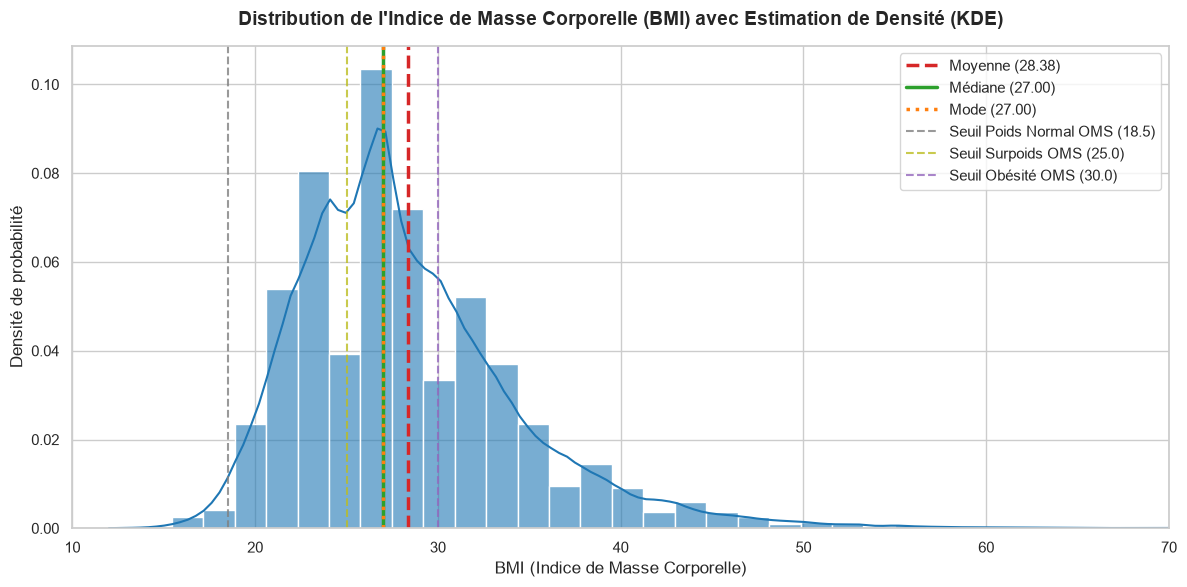

In [3]:
# Graphique 1 : Histogramme et Courbe de Densité (KDE)
plt.figure(figsize=(12, 6))

sns.histplot(bmi, bins=50, kde=True, color='#1f77b4', edgecolor='white', stat='density', alpha=0.6)

# Repères de tendance centrale
plt.axvline(moyenne, color='#d62728', linestyle='--', linewidth=2.5, label=f'Moyenne ({moyenne:.2f})')
plt.axvline(mediane, color='#2ca02c', linestyle='-', linewidth=2.5, label=f'Médiane ({mediane:.2f})')
plt.axvline(mode_val, color='#ff7f0e', linestyle=':', linewidth=2.5, label=f'Mode ({mode_val:.2f})')

# Seuils de référence de l'OMS
plt.axvline(18.5, color='gray', linestyle='--', alpha=0.8, label='Seuil Poids Normal OMS (18.5)')
plt.axvline(25.0, color='#bcbd22', linestyle='--', alpha=0.8, label='Seuil Surpoids OMS (25.0)')
plt.axvline(30.0, color='#9467bd', linestyle='--', alpha=0.8, label='Seuil Obésité OMS (30.0)')

plt.title("Distribution de l'Indice de Masse Corporelle (BMI) avec Estimation de Densité (KDE)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("BMI (Indice de Masse Corporelle)", fontsize=12)
plt.ylabel("Densité de probabilité", fontsize=12)
plt.xlim(10, 70)
plt.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.show()


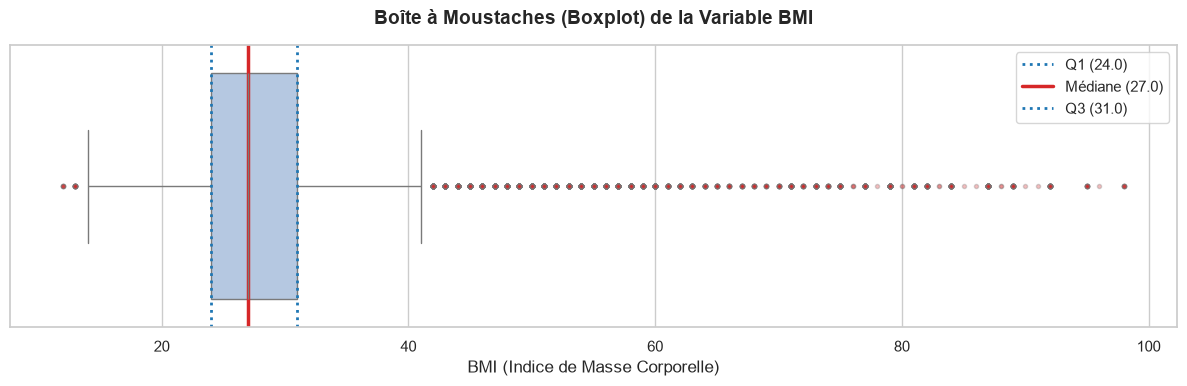

In [4]:
# Graphique 2 : Boîte à moustaches (Boxplot)
fig, ax = plt.subplots(figsize=(12, 4))

sns.boxplot(x=bmi, color='#aec7e8', flierprops=dict(marker='o', markersize=3, markerfacecolor='#d62728', alpha=0.3))

# Ajout des lignes de repère pour Q1, Médiane et Q3
ax.axvline(q1, color='#1f77b4', linestyle=':', linewidth=2, label=f'Q1 ({q1:.1f})')
ax.axvline(mediane, color='#d62728', linestyle='-', linewidth=2.5, label=f'Médiane ({mediane:.1f})')
ax.axvline(q3, color='#1f77b4', linestyle=':', linewidth=2, label=f'Q3 ({q3:.1f})')

ax.set_title("Boîte à Moustaches (Boxplot) de la Variable BMI", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("BMI (Indice de Masse Corporelle)", fontsize=12)
ax.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.show()


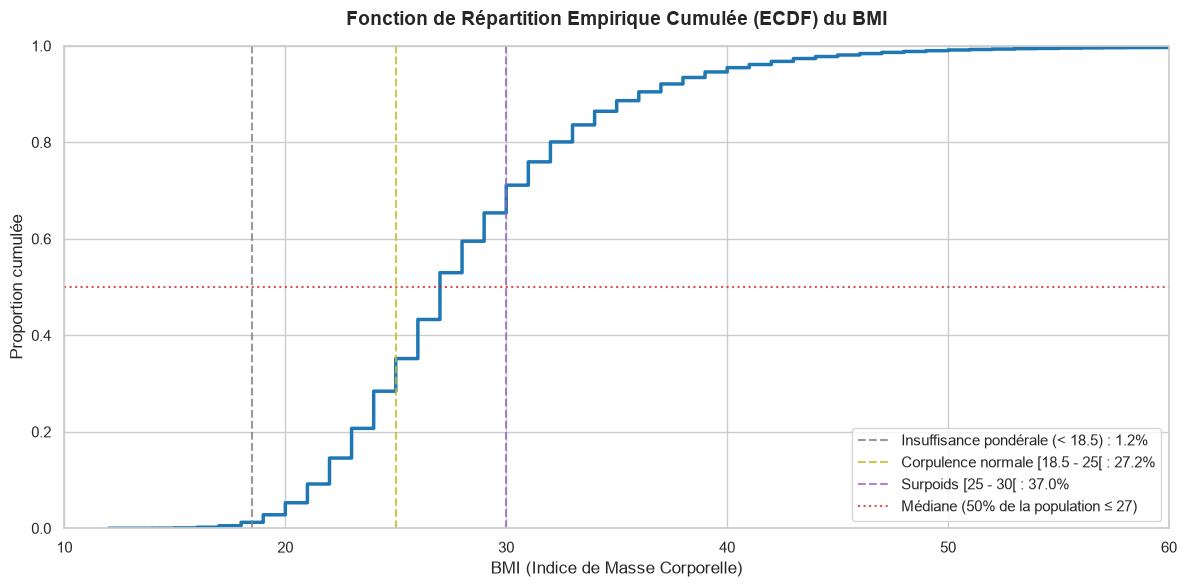

--- Répartition épidémiologique selon les seuils OMS ---
• Insuffisance pondérale (BMI < 18.5) : 1.23%
• Corpulence normale (18.5 <= BMI < 25) : 27.18%
• Surpoids (25 <= BMI < 30) : 36.96%
• Obésité (BMI >= 30) : 34.63%
• Total Surpoids + Obésité : 71.59%


In [5]:
# Graphique 3 : Fonction de Répartition Empirique Cumulée (ECDF)
plt.figure(figsize=(12, 6))

sns.ecdfplot(bmi, color='#1f77b4', linewidth=2.5)

# Calcul des proportions cumulées réelles
pct_underweight = (bmi < 18.5).mean() * 100
pct_normal = ((bmi >= 18.5) & (bmi < 25.0)).mean() * 100
pct_overweight = ((bmi >= 25.0) & (bmi < 30.0)).mean() * 100
pct_obese = (bmi >= 30.0).mean() * 100

plt.axvline(18.5, color='gray', linestyle='--', alpha=0.8, label=f'Insuffisance pondérale (< 18.5) : {pct_underweight:.1f}%')
plt.axvline(25.0, color='#bcbd22', linestyle='--', alpha=0.8, label=f'Corpulence normale [18.5 - 25[ : {pct_normal:.1f}%')
plt.axvline(30.0, color='#9467bd', linestyle='--', alpha=0.8, label=f'Surpoids [25 - 30[ : {pct_overweight:.1f}%')

plt.axhline(0.5, color='#d62728', linestyle=':', alpha=0.8, label=f'Médiane (50% de la population ≤ {mediane:.0f})')

plt.title("Fonction de Répartition Empirique Cumulée (ECDF) du BMI", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("BMI (Indice de Masse Corporelle)", fontsize=12)
plt.ylabel("Proportion cumulée", fontsize=12)
plt.xlim(10, 60)
plt.legend(frameon=True, facecolor='white', loc='lower right')
plt.tight_layout()
plt.show()

print(f"--- Répartition épidémiologique selon les seuils OMS ---")
print(f"• Insuffisance pondérale (BMI < 18.5) : {pct_underweight:.2f}%")
print(f"• Corpulence normale (18.5 <= BMI < 25) : {pct_normal:.2f}%")
print(f"• Surpoids (25 <= BMI < 30) : {pct_overweight:.2f}%")
print(f"• Obésité (BMI >= 30) : {pct_obese:.2f}%")
print(f"• Total Surpoids + Obésité : {(pct_overweight + pct_obese):.2f}%")


### Synthèse des Visualisations Graphiques
- **Histogramme et KDE** : Confirment visuellement l'asymétrie positive ($Skewness = 2.12$). Le pic de densité est centré autour de $27$, et la moyenne ($28.38$) est déplacée vers la droite par les fortes valeurs.
- **Boxplot** : Montre la boîte interquartile située entre $24.0$ et $31.0$. La moustache supérieure s'arrête à $41.5$ ($Q_3 + 1.5 \times IQR$) ; tous les points au-delà représentent des individus présentant des indices d'obésité extrême à morbide, expliquant le fort coefficient d'aplatissement ($Kurtosis = 11.00$).
- **ECDF** : Montre que près de **$72.6\%$** de la population se trouve en situation de surpoids ou d'obésité ($\text{BMI} \ge 25$), soulignant l'importance critique de cette variable dans l'évaluation des risques liés au diabète.
